<a href="https://colab.research.google.com/github/Homnath123/Lightweight-ML-Healthcare-AI-IoT/blob/main/MachineLearning_Predictions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# -----------------------------------------------------------------------------
# STEP 1: LOAD THE DATA
# Upload the Kaggle CSV through Colab, read it (the file is semicolon-separated),
# and check its size, column types, missing values, and class balance.
# -----------------------------------------------------------------------------
from google.colab import files
import pandas as pd
import numpy as np

uploaded = files.upload()                 # opens the "Choose files" button
csv_name = list(uploaded.keys())[0]       # name of the uploaded file

df = pd.read_csv(csv_name, sep=";")
df.columns = df.columns.str.strip()       # remove stray spaces in column names

print("Rows, Columns:", df.shape)
print("\nColumn types:\n", df.dtypes)
print("\nMissing values:\n", df.isnull().sum())

TARGET = "cardio"
print(df[TARGET].value_counts())          # confirms classes are balanced (~50/50)
df.head()

Saving cardio_train.csv to cardio_train (1).csv
Rows, Columns: (70000, 15)

Column types:
 id               int64
age              int64
gender           int64
height           int64
weight         float64
ap_hi            int64
ap_lo            int64
cholesterol      int64
gluc             int64
smoke            int64
alco             int64
active           int64
cardio           int64
Unnamed: 13     object
               float64
dtype: object

Missing values:
 id                 0
age                0
gender             0
height             0
weight             0
ap_hi              0
ap_lo              0
cholesterol        0
gluc               0
smoke              0
alco               0
active             0
cardio             0
Unnamed: 13    69999
               70000
dtype: int64
cardio
0    35021
1    34979
Name: count, dtype: int64


/tmp/ipykernel_4016/765203591.py:13: DtypeWarning: Columns (13) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(csv_name, sep=";")


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,Unnamed: 13,
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0,NaN,NaN
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1,NaN,NaN
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1,NaN,NaN
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1,NaN,NaN
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0,NaN,NaN


In [ ]:
# -----------------------------------------------------------------------------
# STEP 2: INSPECT DATA QUALITY
# Look at min/max of every column to spot data-entry errors (e.g. blood pressure
# in the thousands, negative values, implausible heights). Also count duplicate
# records, ignoring the id column. Report these findings in the paper.
# -----------------------------------------------------------------------------
print(df.describe().T[["min", "max"]])
print("Duplicates (excluding id):", df.drop(columns="id").duplicated().sum())

                 min      max
id               0.0  99999.0
age          10798.0  23713.0
gender           1.0      2.0
height          55.0    250.0
weight          10.0    200.0
ap_hi         -150.0  16020.0
ap_lo          -70.0  11000.0
cholesterol      1.0      3.0
gluc             1.0      3.0
smoke            0.0      1.0
alco             0.0      1.0
active           0.0      1.0
cardio           0.0      1.0
                 NaN      NaN
Duplicates (excluding id): 24


Load the Data


In [ ]:
# -----------------------------------------------------------------------------
# STEP 3: CLEAN DATA AND ENGINEER FEATURES
# Reloads the raw CSV every time, so this cell can be re-run safely.
# - Strip whitespace, convert every column to numeric (blank/invalid -> NaN),
#   then drop rows with any missing value.
# - Convert age from days to years; create BMI = weight / height(m)^2.
# - Remove implausible records:
#     systolic BP (ap_hi): 80-250    diastolic BP (ap_lo): 40-200
#     systolic must exceed diastolic
#     height: 120-220 cm             weight: 30-200 kg
# - Drop id and the original age column, then remove duplicate rows.
# -----------------------------------------------------------------------------
df = pd.read_csv(csv_name, sep=";", skipinitialspace=True)
df.columns = df.columns.str.strip()
df = df.loc[:, df.columns != ""]
df = df.loc[:, ~df.columns.str.startswith("Unnamed")]
df = df.dropna(axis=1, how="all")

# Convert every column to numeric; blanks like ' ' become NaN
df = df.apply(pd.to_numeric, errors="coerce")

n_before = len(df)
print("Missing values per column before dropping:\n", df.isnull().sum())
df = df.dropna()                      # remove rows with any missing value

df["age_years"] = (df["age"] / 365.25).round().astype(int)
df["bmi"] = df["weight"] / (df["height"] / 100) ** 2

df = df[
    df["ap_hi"].between(80, 250) &
    df["ap_lo"].between(40, 200) &
    (df["ap_hi"] > df["ap_lo"]) &
    df["height"].between(120, 220) &
    df["weight"].between(30, 200)
]
df = df.drop(columns=["id", "age"]).drop_duplicates()

removed = n_before - len(df)
print(f"\nRemoved {removed} rows ({removed / n_before:.1%}). Remaining: {len(df)}")
print("Any NaN left:", df.isnull().any().any())      # should print False
print(df.dtypes)                                      # all should be numeric
print(df[TARGET].value_counts(normalize=True))

Missing values per column before dropping:
 id             0
age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco           0
active         0
cardio         0
dtype: int64

Removed 5209 rows (7.4%). Remaining: 64791
Any NaN left: False
gender           int64
height           int64
weight         float64
ap_hi            int64
ap_lo            int64
cholesterol      int64
gluc             int64
smoke            int64
alco             int64
active           int64
cardio           int64
age_years        int64
bmi            float64
dtype: object
cardio
1    0.508759
0    0.491241
Name: proportion, dtype: float64


In [ ]:
# -----------------------------------------------------------------------------
# STEP 4: TRAIN/TEST SPLIT
# 80% training / 20% hold-out test. Stratified so both sets keep the same
# CVD / no-CVD proportion. random_state makes the split reproducible.
# The hold-out set is used for the resource-cost measurements (Step 7), while
# cross-validation (Step 6) uses the full dataset.
# -----------------------------------------------------------------------------
from sklearn.model_selection import train_test_split

X = df.drop(columns=[TARGET])    # input features
y = df[TARGET]                   # label to predict

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)

(51832, 12) (12959, 12)


In [ ]:
# -----------------------------------------------------------------------------
# STEP 5: DEFINE THE CANDIDATE MODELS
# Six lightweight classifiers suitable for edge/IoT deployment. Models that are
# sensitive to feature scale (LogReg, KNN, SVM) are wrapped in a pipeline with
# StandardScaler so scaling is learned only from training data (no leakage).
# Tree depth and forest size are deliberately capped to keep models small.
# -----------------------------------------------------------------------------
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

models = {
    "Logistic Regression":   make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Naive Bayes":           GaussianNB(),
    "KNN (k=5)":             make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Decision Tree (d=6)":   DecisionTreeClassifier(max_depth=6, random_state=42),
    "Linear SVM":            make_pipeline(StandardScaler(), LinearSVC(max_iter=5000)),
    "Random Forest (small)": RandomForestClassifier(n_estimators=50, max_depth=8, random_state=42),
}

In [ ]:
# -----------------------------------------------------------------------------
# STEP 6: 5-FOLD CROSS-VALIDATION (PREDICTIVE PERFORMANCE)
# Evaluate each model on 5 stratified folds of the full dataset and report
# mean +/- standard deviation for accuracy, precision, recall, F1, and ROC-AUC.
# This is more reliable than a single split, because small differences between
# models may be within noise. Use this table as the main results table.
# -----------------------------------------------------------------------------
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

cv_rows = []
for name, m in models.items():
    s = cross_validate(m, X, y, cv=cv, scoring=scoring, n_jobs=-1)
    row = {"Model": name}
    for metric in scoring:
        vals = s[f"test_{metric}"]
        row[metric.capitalize()] = f"{vals.mean():.4f} ± {vals.std():.4f}"
    cv_rows.append(row)

cv_results = pd.DataFrame(cv_rows).set_index("Model")
cv_results

,Accuracy,Precision,Recall,F1,Roc_auc
Model,,,,,
Logistic Regression,0.7240 ± 0.0035,0.7492 ± 0.0046,0.6880 ± 0.0058,0.7172 ± 0.0038,0.7887 ± 0.0036
Naive Bayes,0.7043 ± 0.0023,0.7526 ± 0.0027,0.6240 ± 0.0068,0.6822 ± 0.0038,0.7701 ± 0.0043
KNN (k=5),0.6859 ± 0.0033,0.6947 ± 0.0041,0.6826 ± 0.0053,0.6886 ± 0.0033,0.7347 ± 0.0026
Decision Tree (d=6),0.7255 ± 0.0043,0.7528 ± 0.0131,0.6866 ± 0.0179,0.7178 ± 0.0054,0.7906 ± 0.0045
Linear SVM,0.7233 ± 0.0030,0.7518 ± 0.0037,0.6810 ± 0.0060,0.7146 ± 0.0037,0.7885 ± 0.0035
Random Forest (small),0.7287 ± 0.0044,0.7660 ± 0.0060,0.6723 ± 0.0078,0.7160 ± 0.0051,0.7956 ± 0.0038


In [ ]:
# -----------------------------------------------------------------------------
# STEP 7: RESOURCE COST ON THE HOLD-OUT SET (EDGE/IoT SUITABILITY)
# For each model, train on the training set and measure:
#   - Train (s)               : time to fit the model
#   - Inference (ms/sample)   : average prediction time per patient
#   - Size (KB)               : serialized model size (pickle), a proxy for memory
#   - False Negatives         : missed CVD cases (most costly error in screening)
# Also records the standard metrics on the hold-out data.
# Note: timings depend on Colab hardware, so treat them as relative comparisons.
# -----------------------------------------------------------------------------
import time, pickle
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

rows = []
for name, m in models.items():
    t0 = time.perf_counter()
    m.fit(X_train, y_train)
    train_s = time.perf_counter() - t0

    t0 = time.perf_counter()
    pred = m.predict(X_test)
    infer_ms = (time.perf_counter() - t0) / len(X_test) * 1000

    # ROC-AUC needs a continuous score: use decision_function if available,
    # otherwise the predicted probability of the positive class
    score = m.decision_function(X_test) if hasattr(m, "decision_function") \
            else m.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()

    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, score),
        "False Negatives": fn,
        "Train (s)": train_s,
        "Inference (ms/sample)": infer_ms,
        "Size (KB)": len(pickle.dumps(m)) / 1024,
    })

results = pd.DataFrame(rows).set_index("Model").round(4)
results.sort_values("F1", ascending=False)

,Accuracy,Precision,Recall,F1,ROC-AUC,False Negatives,Train (s),Inference (ms/sample),Size (KB)
Model,,,,,,,,,
Logistic Regression,0.7291,0.7568,0.6891,0.7213,0.7943,2050,0.3642,0.0008,1.6436
Decision Tree (d=6),0.7281,0.7547,0.6898,0.7208,0.7939,2045,0.1158,0.0002,11.2266
Random Forest (small),0.7334,0.7737,0.6727,0.7197,0.8007,2158,1.5777,0.0042,1664.8682
Linear SVM,0.7288,0.7600,0.6825,0.7192,0.7941,2093,0.2236,0.0003,1.5215
KNN (k=5),0.6916,0.7002,0.6888,0.6944,0.7384,2052,0.2205,0.3821,6118.9463
Naive Bayes,0.7104,0.7620,0.6264,0.6876,0.7781,2463,0.0304,0.0005,1.1279


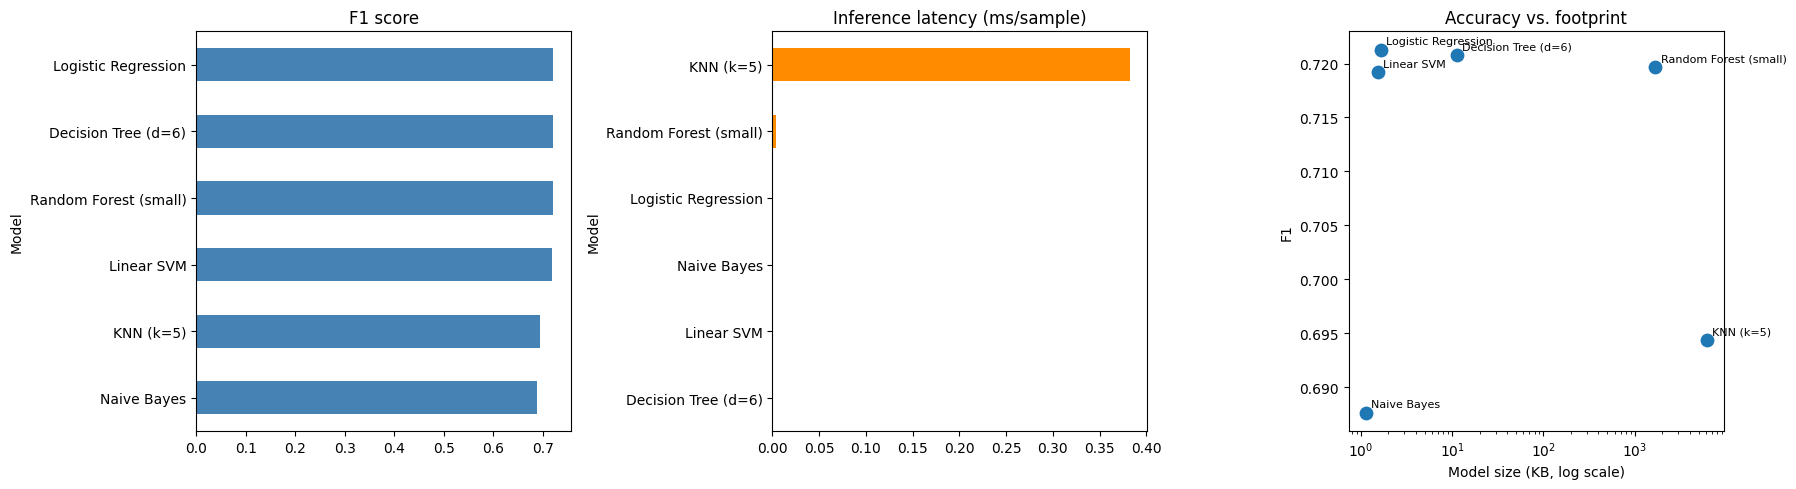

In [ ]:
# -----------------------------------------------------------------------------
# STEP 8: FIGURES FOR THE PAPER
# Three panels: (1) F1 score, (2) inference latency, (3) accuracy-vs-footprint
# trade-off (F1 against model size on a log scale). Models in the top-left of
# panel 3 (high F1, small size) are the best candidates for edge deployment.
# Saved as comparison.png at 300 dpi for publication quality.
# -----------------------------------------------------------------------------
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

results["F1"].sort_values().plot.barh(ax=axes[0], color="steelblue")
axes[0].set_title("F1 score")

results["Inference (ms/sample)"].sort_values().plot.barh(ax=axes[1], color="darkorange")
axes[1].set_title("Inference latency (ms/sample)")

axes[2].scatter(results["Size (KB)"], results["F1"], s=80)
for name, r in results.iterrows():
    axes[2].annotate(name, (r["Size (KB)"], r["F1"]), fontsize=8,
                     xytext=(4, 4), textcoords="offset points")
axes[2].set_xscale("log")
axes[2].set_xlabel("Model size (KB, log scale)")
axes[2].set_ylabel("F1")
axes[2].set_title("Accuracy vs. footprint")

plt.tight_layout()
plt.savefig("comparison.png", dpi=300)
plt.show()

,Logistic Regression,Naive Bayes,KNN (k=5),Decision Tree (d=6),Linear SVM,Random Forest (small)
ap_hi,0.1405,0.0704,0.0923,0.1363,0.1383,0.1212
cholesterol,0.0211,0.0242,0.0249,0.0240,0.0214,0.0242
age_years,0.0206,0.0099,0.0207,0.0331,0.0222,0.0120
bmi,0.0014,0.0026,0.0029,0.0015,0.0022,0.0050
ap_lo,0.0022,0.0248,0.0167,0.0095,0.0036,0.0027
active,0.0013,-0.0002,0.0026,0.0000,0.0015,0.0021
weight,0.0076,0.0015,0.0003,0.0002,0.0109,0.0008
height,0.0007,0.0002,-0.0003,0.0000,0.0009,-0.0000
alco,0.0009,0.0001,0.0005,-0.0001,0.0011,-0.0001
smoke,0.0003,0.0011,0.0028,0.0000,0.0009,-0.0003


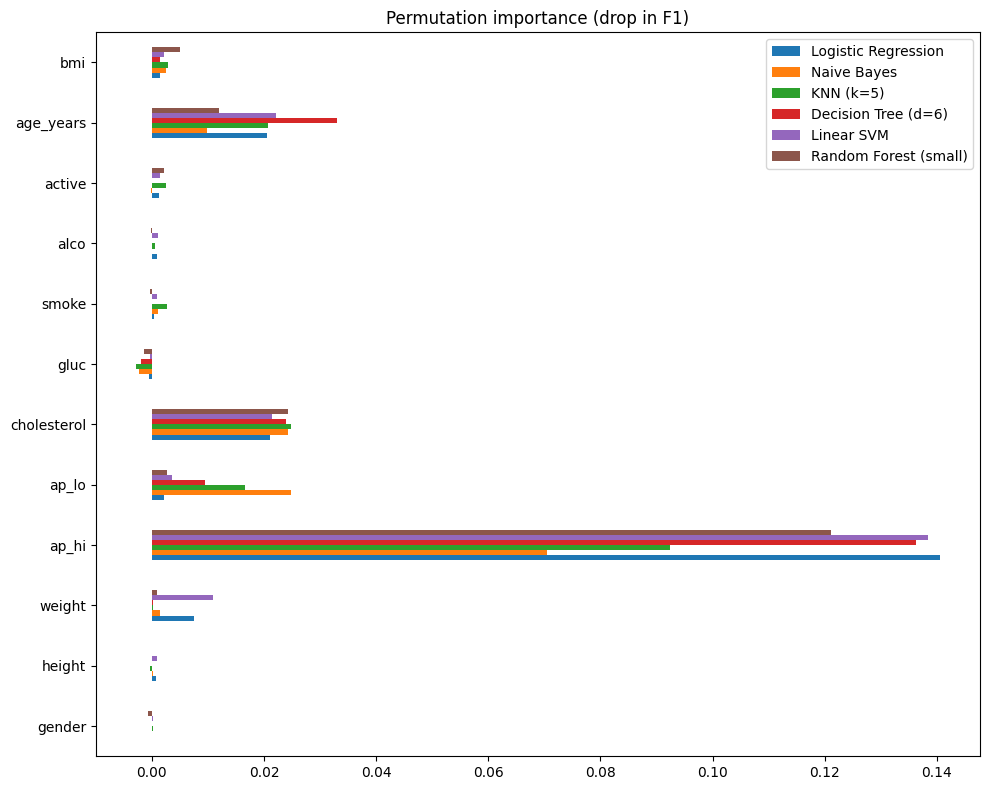

In [ ]:
# -----------------------------------------------------------------------------
# STEP 9: FEATURE IMPORTANCE ACROSS ALL MODELS (PERMUTATION IMPORTANCE)
# Shuffle one feature at a time on the hold-out set and measure how much the
# F1 score drops. A bigger drop means the model relies on that feature more.
# This works for every model, so the results are directly comparable.
# Run after Step 7, so all models have been fitted.
# -----------------------------------------------------------------------------
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt

imp_all = {}
for name, m in models.items():
    r = permutation_importance(m, X_test, y_test, scoring="f1",
                               n_repeats=5, random_state=42, n_jobs=-1)
    imp_all[name] = r.importances_mean

imp_df = pd.DataFrame(imp_all, index=X.columns)

# Heatmap-style table: rows = features, columns = models
display(imp_df.round(4).sort_values("Random Forest (small)", ascending=False))

imp_df.plot.barh(figsize=(10, 8), title="Permutation importance (drop in F1)")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=300)
plt.show()

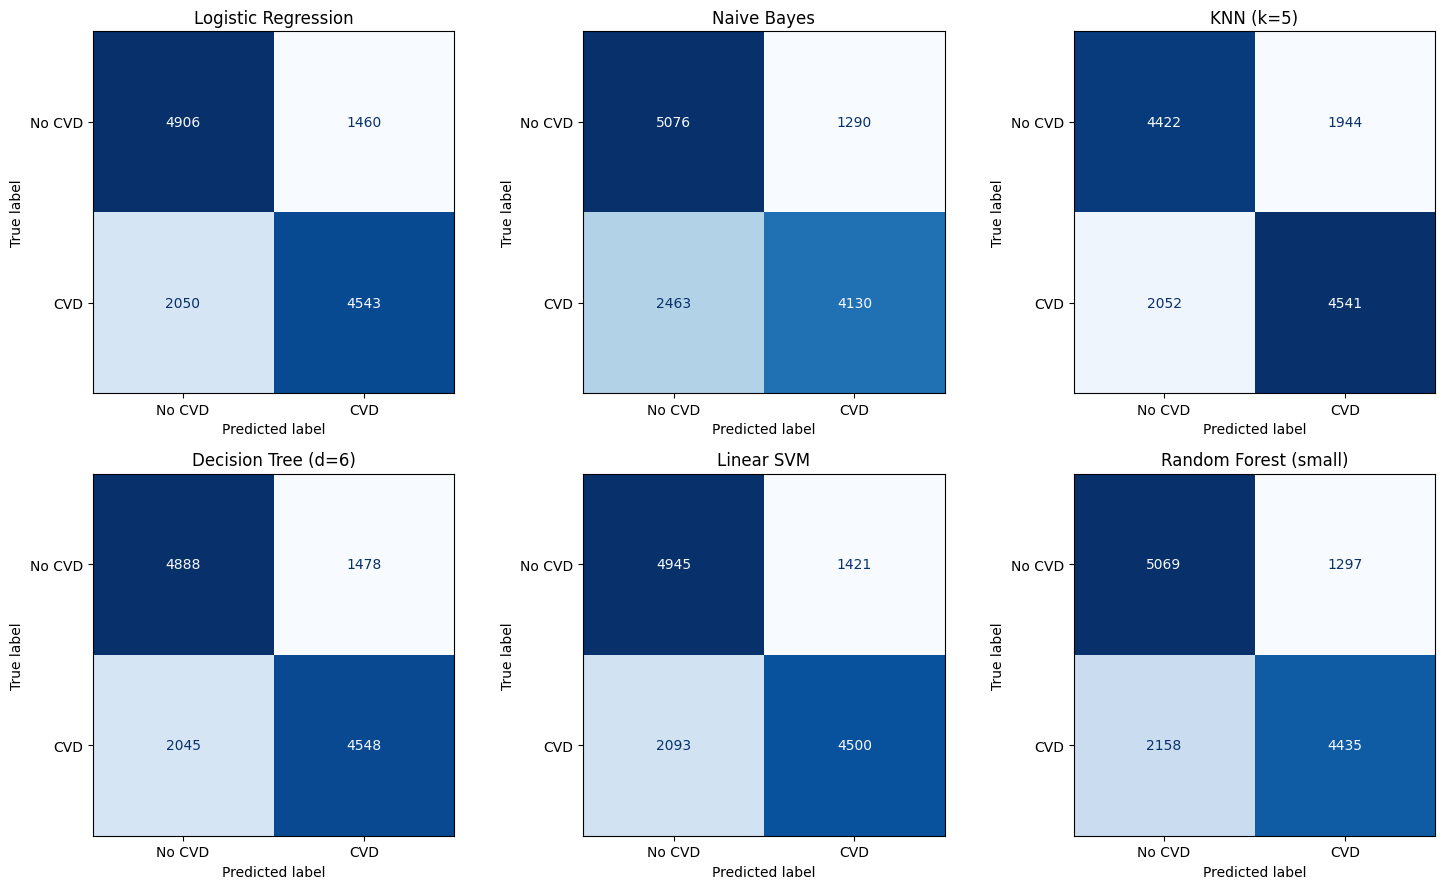

,TN,FP,FN,TP,Sensitivity (recall),Specificity
Model,,,,,,
Logistic Regression,4906,1460,2050,4543,0.6891,0.7707
Naive Bayes,5076,1290,2463,4130,0.6264,0.7974
KNN (k=5),4422,1944,2052,4541,0.6888,0.6946
Decision Tree (d=6),4888,1478,2045,4548,0.6898,0.7678
Linear SVM,4945,1421,2093,4500,0.6825,0.7768
Random Forest (small),5069,1297,2158,4435,0.6727,0.7963


In [ ]:
# -----------------------------------------------------------------------------
# STEP 10: CONFUSION MATRICES (HOLD-OUT SET)
# Shows, for each model, how many patients were correctly and incorrectly
# classified. Bottom-left cell = false negatives (missed CVD cases), the most
# costly error in a screening setting. Also saves a table of TN/FP/FN/TP counts.
# Run after Step 7, so all models have been fitted.
# -----------------------------------------------------------------------------
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, m) in zip(axes.ravel(), models.items()):
    ConfusionMatrixDisplay.from_estimator(
        m, X_test, y_test, display_labels=["No CVD", "CVD"],
        cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=300)
plt.show()

# Table of counts (useful for the results section)
cm_rows = []
for name, m in models.items():
    tn, fp, fn, tp = confusion_matrix(y_test, m.predict(X_test)).ravel()
    cm_rows.append({"Model": name, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
                    "Sensitivity (recall)": tp / (tp + fn),
                    "Specificity": tn / (tn + fp)})
pd.DataFrame(cm_rows).set_index("Model").round(4)

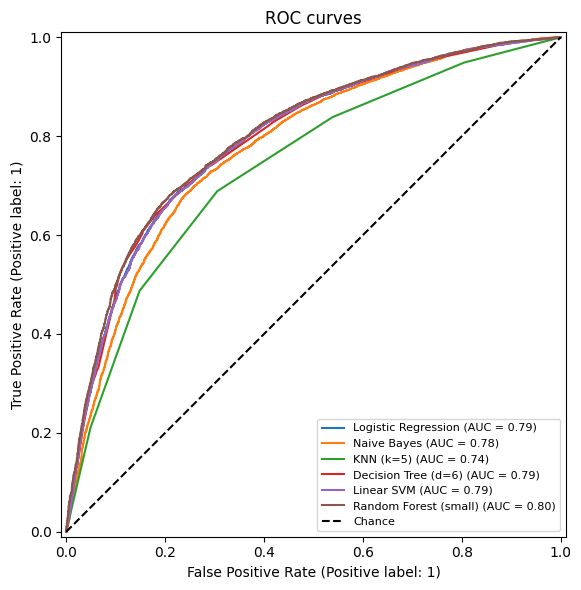

In [ ]:
# -----------------------------------------------------------------------------
# STEP 11: ROC CURVES (HOLD-OUT SET)
# Plots true-positive rate against false-positive rate for every model on one
# axis. A curve closer to the top-left corner means better discrimination.
# The legend shows each model's AUC.
# -----------------------------------------------------------------------------
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(7, 6))
for name, m in models.items():
    RocCurveDisplay.from_estimator(m, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Chance")
ax.set_title("ROC curves")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig("roc_curves.png", dpi=300)
plt.show()

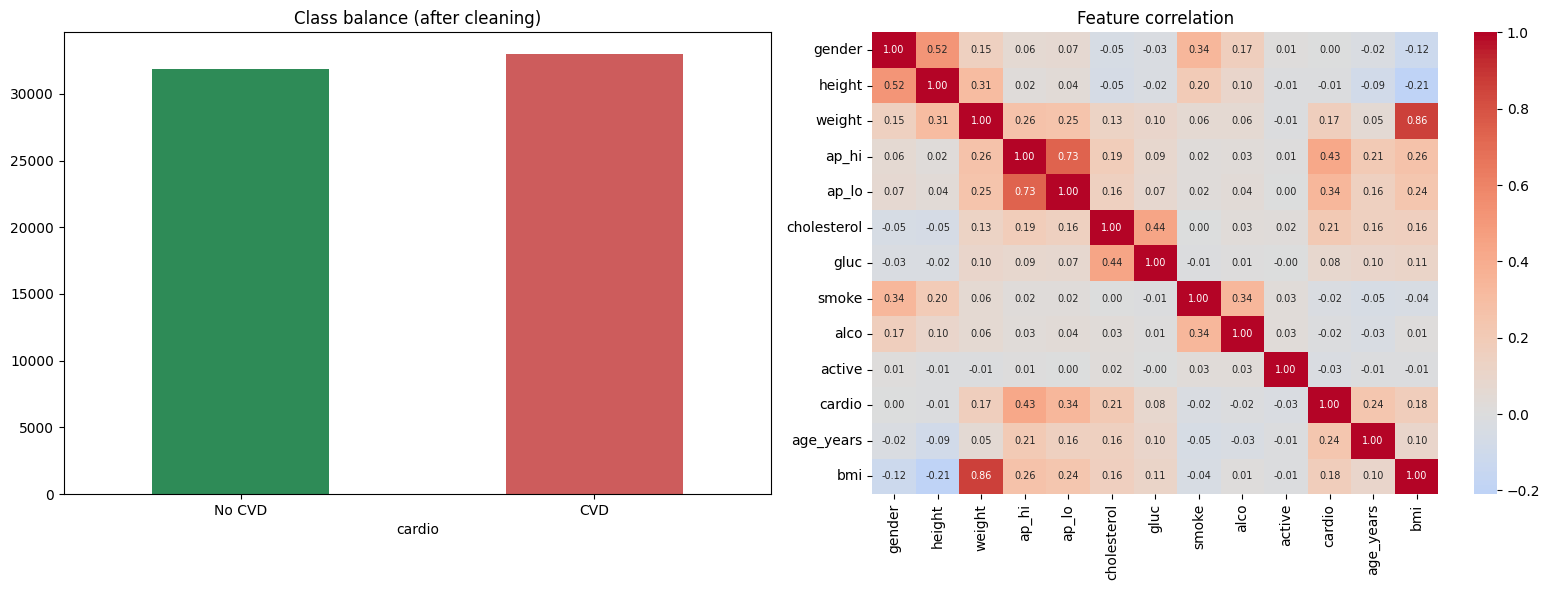

In [ ]:
# -----------------------------------------------------------------------------
# STEP 12: DATA EXPLORATION PLOTS
# Left: class balance after cleaning. Right: correlation between all features
# and the target. Shows which features relate to CVD and which are redundant
# (e.g. weight and bmi).
# -----------------------------------------------------------------------------
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
df[TARGET].value_counts().sort_index().plot.bar(ax=axes[0], color=["seagreen", "indianred"])
axes[0].set_xticklabels(["No CVD", "CVD"], rotation=0)
axes[0].set_title("Class balance (after cleaning)")

sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0,
            ax=axes[1], annot_kws={"size": 7})
axes[1].set_title("Feature correlation")
plt.tight_layout()
plt.savefig("eda.png", dpi=300)
plt.show()

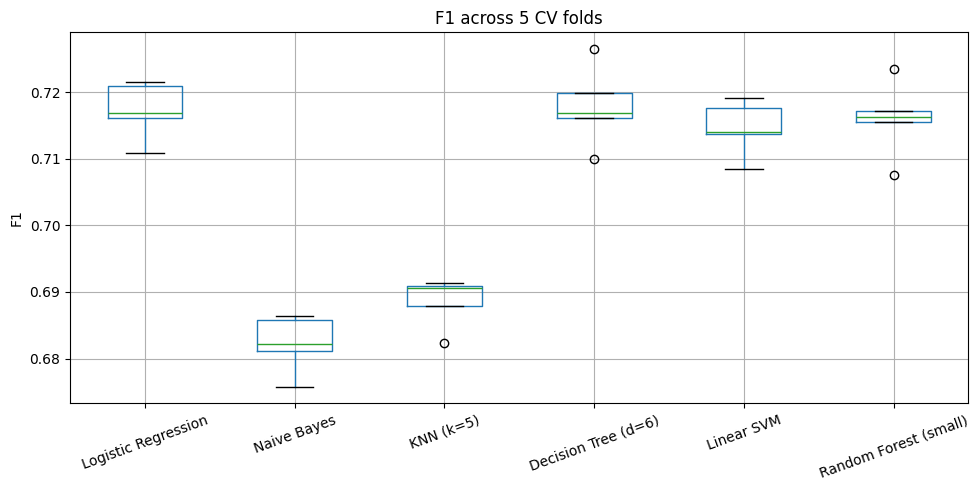

In [ ]:
# -----------------------------------------------------------------------------
# STEP 13: F1 DISTRIBUTION ACROSS CV FOLDS
# Boxplot of the 5 fold scores per model. Overlapping boxes show that the
# differences between the top models are within noise.
# -----------------------------------------------------------------------------
fold_f1 = {}
for name, m in models.items():
    fold_f1[name] = cross_validate(m, X, y, cv=cv, scoring="f1", n_jobs=-1)["test_score"]

pd.DataFrame(fold_f1).boxplot(figsize=(10, 5), rot=20)
plt.ylabel("F1")
plt.title("F1 across 5 CV folds")
plt.tight_layout()
plt.savefig("cv_boxplot.png", dpi=300)
plt.show()

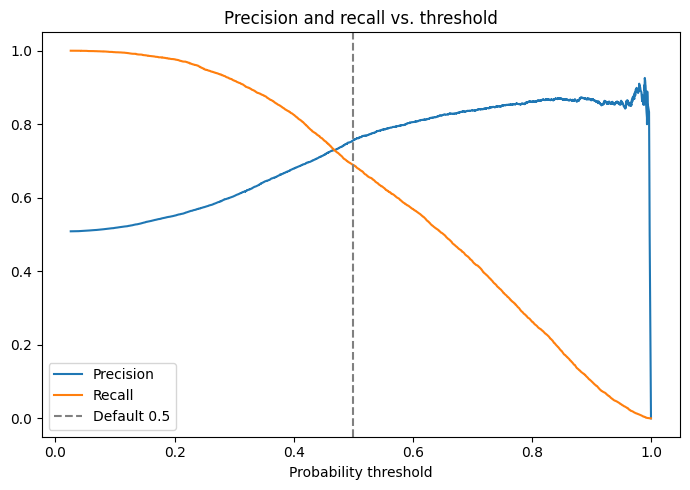

In [ ]:
# -----------------------------------------------------------------------------
# STEP 14: DECISION THRESHOLD TRADE-OFF (LOGISTIC REGRESSION)
# Lowering the probability cutoff catches more CVD cases (higher recall) at the
# cost of more false alarms (lower precision). Choose a cutoff based on how
# costly a missed case is in screening.
# -----------------------------------------------------------------------------
from sklearn.metrics import precision_recall_curve

proba = models["Logistic Regression"].predict_proba(X_test)[:, 1]
prec, rec, thr = precision_recall_curve(y_test, proba)

plt.figure(figsize=(7, 5))
plt.plot(thr, prec[:-1], label="Precision")
plt.plot(thr, rec[:-1], label="Recall")
plt.axvline(0.5, color="gray", ls="--", label="Default 0.5")
plt.xlabel("Probability threshold")
plt.legend()
plt.title("Precision and recall vs. threshold")
plt.tight_layout()
plt.savefig("threshold_tradeoff.png", dpi=300)
plt.show()

In [ ]:
import joblib, sklearn
print(sklearn.__version__)   # note this; use the same version in the backend

best = models["Logistic Regression"]
best.fit(X, y)               # refit on all data for deployment

joblib.dump({"model": best, "columns": list(X.columns)}, "cvd_model.joblib")
files.download("cvd_model.joblib")

1.6.1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>